In [61]:
% pip install pandas
% pip install numpy
% pip install matplotlib
% pip install scikit-learn
% pip install progress
% pip install scikit-bio
 
% git clone https://github.com/aleixalcacer/archetypes
% pip install "archetypes/"

UsageError: Line magic function `%` not found.


In [1]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os

from archetypes import AA
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset
import json

Couldn't import dot_parser, loading of dot files will not be possible.


## Performing AA

In [5]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = "hadza_otu_nov.tsv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_table(os.path.join(dataDir, otuFile), index_col=0)
tax = pd.read_table(os.path.join(dataDir, taxFile), index_col=0)

In [6]:
FRAC = 0.05
otu_sample = otu.sample(frac=FRAC)

In [7]:
# ------tax_glom() equivalent------

group = "Genus" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

grouped_cols = tax[group].unique()

otu_grouped = pd.DataFrame(index=otu_sample.index, columns=grouped_cols)

i = 0
for c in tqdm(otu_sample.columns):
    grp_col = tax[group][c]
    
    if(pd.isnull(otu_grouped[grp_col]).all()):
        otu_grouped[grp_col] = otu_sample[c]
        continue

    otu_grouped[grp_col] = otu_grouped[grp_col] + otu_sample[c]
    # print(f"Processed column ({i+1}/{len(otu.columns)}): {grp_col}")

    i += 1

otu_grouped.columns = otu_grouped.columns.astype(str)


  0%|          | 0/2647 [00:00<?, ?it/s]

100%|██████████| 2647/2647 [00:00<00:00, 3753.93it/s]


In [8]:
otu_log = otu_grouped.copy()
otu_log = otu_log.map(lambda x: np.log2(x+1))

c:\Users\rayve\.conda\envs\GHG_Work\Lib\site-packages\skbio\stats\ordination\_principal_coordinate_analysis.py:146: RuntimeWarning: The result contains negative eigenvalues. Please compare their magnitude with the magnitude of some of the largest positive eigenvalues. If the negative ones are smaller, it's probably safe to ignore them, but if they are large in magnitude, the results won't be useful. See the Notes section for more details. The smallest eigenvalue is -0.7440024923454168 and the largest is 50.24731691081123.
  warn(


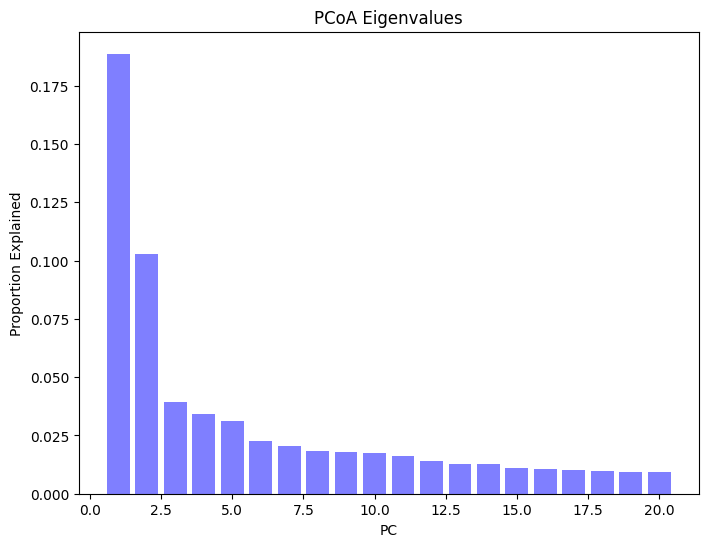

In [9]:
import scipy.spatial
from skbio.tree import TreeNode
from skbio.diversity import beta_diversity
from skbio.stats.ordination import pcoa
import scipy

# metadata = pd.read_table('metadata.tsv', index_col=0)
pcoa_data = otu_log.copy()

method = 'braycurtis' #scipy.spatial.distance.jensenshannon  #'jensenshannon' or 'bray_curtis', unifrac is problematic
bdiv = beta_diversity(
    method, pcoa_data, ids=pcoa_data.index, pairwise_func=scipy.spatial.distance.pdist
)
# Perform PCoA
pcoa_results = pcoa(bdiv, number_of_dimensions=20)

# Plot the PCoA Eigenvalues and proportions explained

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.bar(range(1, len(pcoa_results.eigvals) + 1), pcoa_results.proportion_explained, color="blue", alpha=0.5, align="center")
ax.set_xlabel("PC")
ax.set_ylabel("Proportion Explained")
ax.set_title("PCoA Eigenvalues")
plt.show()



In [10]:
NUM_PC = 7
# Extract the coordinates
pcoa_coordinates = pcoa_results.samples[[f"PC{i}" for i in range(1, NUM_PC+1)]]

C:\Users\rayve\AppData\Local\Temp\ipykernel_18908\1046707342.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_18908\1046707342.py:9: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")


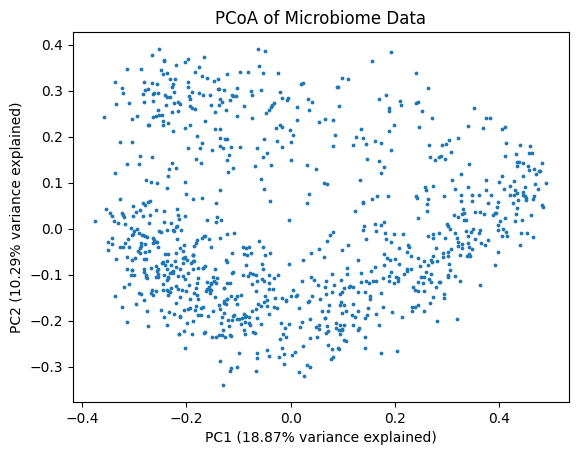

In [11]:
import matplotlib.pyplot as plt

# Create a scatter plot

plt.scatter(pcoa_coordinates['PC1'], pcoa_coordinates['PC2'], s=3)

# Add labels and title
plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")
plt.title("PCoA of Microbiome Data")

# # Add sample labels if desired
# for idx, row in pcoa_coordinates.iterrows():
#     plt.annotate(idx, (row['PC1'], row['PC2']))

plt.show()



In [12]:
# from archetypes.numpy._aa_3 import AA_3
from archetypes import AA

AA_data = pcoa_coordinates.to_numpy()

method_kwargs = {
    "max_iter_optimizer": 10,
}

N_ARCHETYPES = 3
aa = AA(n_archetypes=N_ARCHETYPES, method="pgd", method_kwargs=method_kwargs, random_state=3)


aa.fit(AA_data)

print(aa.archetypes_)

[[-0.18666341 -0.25643802  0.00863434  0.02551219  0.00048195  0.00765336
  -0.01266472]
 [-0.23690722  0.33324453 -0.02916715 -0.03553649  0.00870141 -0.03678836
   0.0112738 ]
 [ 0.42473251  0.05475404  0.01166366 -0.01302432 -0.03086367  0.00914418
   0.00051292]]


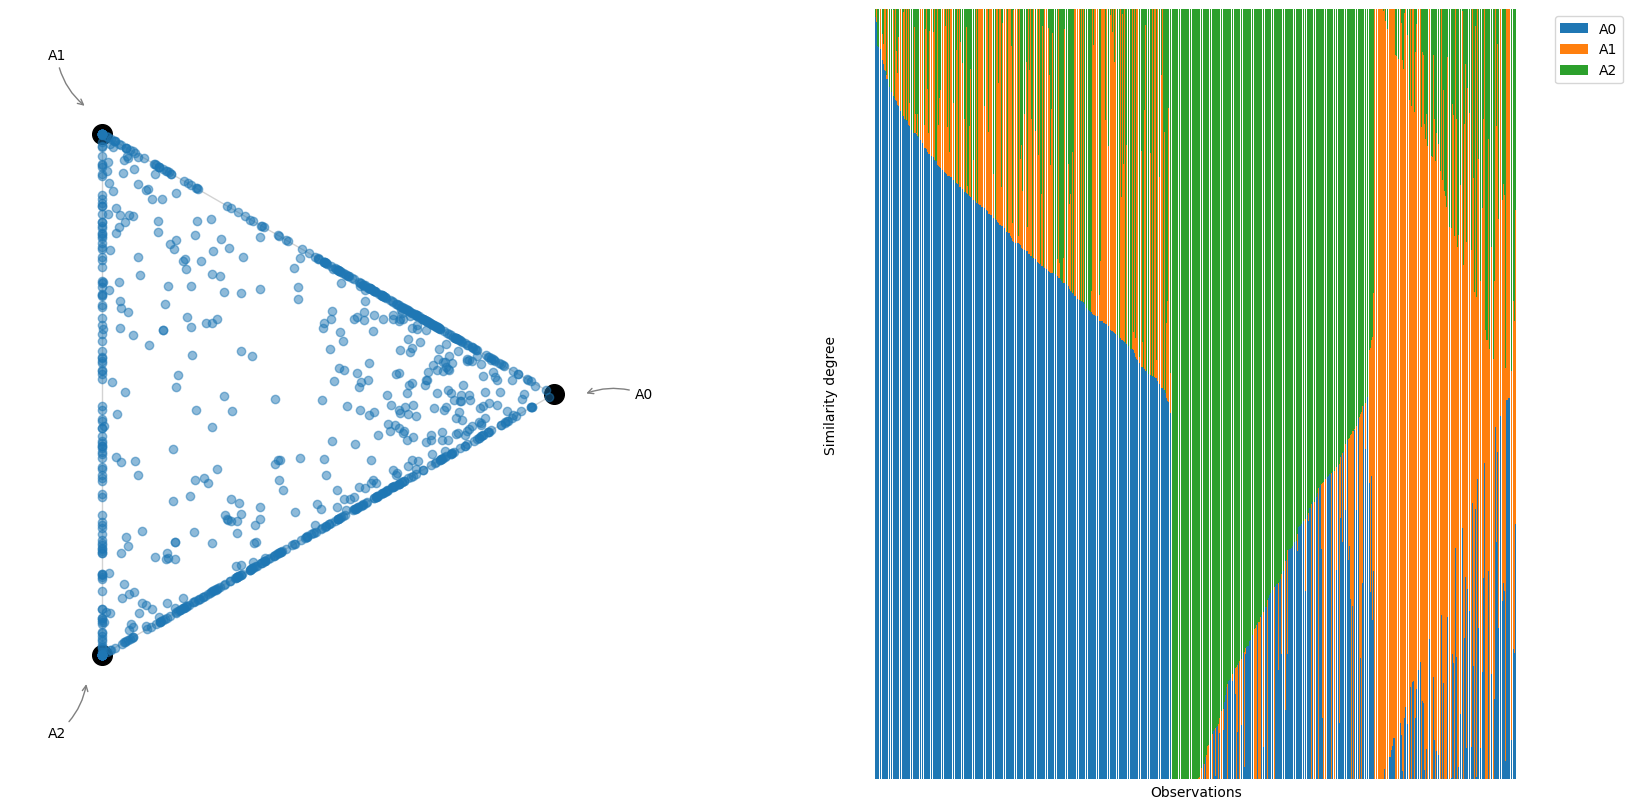

In [13]:
data_sorted, info = sort_by_archetype_similarity(AA_data, [aa.similarity_degree_], aa.archetypes_)

similarity_degree_permuted, _ = permute_dataset(aa.similarity_degree_, info["perms"])

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
simplex(aa.similarity_degree_, alpha=0.5, ax=ax[0], show_vertices=True)
stacked_bar(similarity_degree_permuted, ax=ax[1])

plt.show()


C:\Users\rayve\AppData\Local\Temp\ipykernel_18908\254064229.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
C:\Users\rayve\AppData\Local\Temp\ipykernel_18908\254064229.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")


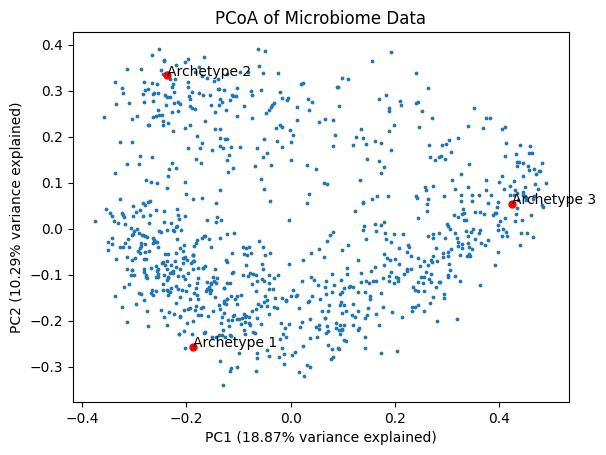

In [14]:
plt.scatter(pcoa_coordinates['PC1'], pcoa_coordinates['PC2'], s=3)

# Add labels and title
plt.xlabel(f"PC1 ({pcoa_results.proportion_explained[0]:.2%} variance explained)")
plt.ylabel(f"PC2 ({pcoa_results.proportion_explained[1]:.2%} variance explained)")
plt.title("PCoA of Microbiome Data")

plt.scatter(aa.archetypes_[:, 0], aa.archetypes_[:, 1], c="red", s=25)
for i, arch in enumerate(aa.archetypes_):
    plt.text(arch[0], arch[1], f"Archetype {i+1}")

# Closest Points to Archetypes
# for i, arch in enumerate(aa.archetypes_):
#     idx = np.argmax(aa.similarity_degree_[:, i])
#     plt.scatter(pcoa_coordinates.iloc[idx]['PC1'], pcoa_coordinates.iloc[idx]['PC2'], c="black", s=25)

plt.show()

In [15]:
otu_aa = pd.DataFrame(aa.similarity_degree_, index=pcoa_coordinates.index, columns=[f"Archetype {i+1}" for i in range(N_ARCHETYPES)])

# Make a json file containing all details for the archetypes
import json
aa_dict = {
    "archetypes": aa.archetypes_.tolist(),
    "similarity_degree": aa.similarity_degree_.tolist(),
    "labels": aa.labels_.tolist(), 
    "index": pcoa_coordinates.index.tolist(),
    "columns": [f"Archetype {i+1}" for i in range(N_ARCHETYPES)], 
    "loss": aa.loss_,
}


In [16]:
methodName = method if isinstance(method, str) else "jensenshannon"

outName = f"otu_AA_{FRAC}_{group}_{methodName}.json"
outPath = os.path.join(outDir, outName)

json.dump(aa_dict, open(outPath, "w"))
# otu_aa.to_csv(outPath, sep="\t")

# Standard Analysis

### Simplex Plotter Utility

In [1]:
### Simplex Plotter
from matplotlib.patches import Patch
import matplotlib.cm as cm


def filter_further(data, further_filter, filter_type): 
    if filter_type == "equals": 
        return data[data.isin(further_filter)]
    elif filter_type == "not_equals":
        return data[~data.isin(further_filter)]
    elif filter_type == "greater_than":
        return data[data > further_filter]
    elif filter_type == "less_than":
        return data[data < further_filter]


def plot_simplex(otu_aa, hadza_sam, filter_cols, 
                cmap_name="tab20", legend_type="discrete", 
                remove_nan=False, further_filter=None, figsize=(15, 15)):
    """ 
    otu_aa: DataFrame
        The archetypal analysis data
    hadza_sam: DataFrame
        The metadata
    filter_cols: list
        The columns to filter the data by (must contain exact column names from metadata)
    cmap_name: str (optional)
        The name of the colormap to use
    legend_type: str (optional)
        The type of legend to use. Can be "discrete" or "continuous"
    remove_nan: bool (optional)
        Whether to remove NaN values from the data
    further_filter: Dict (optional) = {"filter_type": "equals", "value": []}
        Further filter the data by the values in this list
    figsize: tuple (optional)
        The size of the figure
    """

    present_idx = otu_aa.index.intersection(hadza_sam.index)
    present_points = otu_aa.loc[present_idx]

    # Print the number of values dropped
    print(f"Dropped {len(otu_aa) - len(present_points)} data points: Index not found in metadata")

    # For each data point, add the first non-null value from filter_cols to the filter_labels
    filter_labels = pd.Series(index=present_points.index, dtype=str)
    for col in filter_cols:
        filter_labels = filter_labels.fillna(hadza_sam.loc[present_idx, col])

    # If further_filter is not none, filter the dataset by matching values to each further_filter element
    if further_filter is not None:
        present_points = filter_further(present_points, further_filter["filter_type"], further_filter["value"])
        filter_labels = filter_further(filter_labels, further_filter["filter_type"], further_filter["value"])

    if remove_nan:
        nan_idx = filter_labels.index[filter_labels.isnull()]
        present_points = present_points.drop(nan_idx)
        filter_labels = filter_labels.drop(nan_idx)

    if(legend_type == "discrete"):
        unique_colors = {c: i for i, c in enumerate(filter_labels.unique())}
        color = filter_labels.map(unique_colors)

    elif(legend_type == "continuous"):
        unique_colors = filter_labels
        color = filter_labels.astype(float)

    cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    simplex(present_points, alpha=0.5, ax=ax, c=color, cmap = cmap, s=5, vertices_labels=otu_aa.columns)

    def add_discrete_legend(ax, unique_colors, cmap):
        legend_patches = [
            Patch(color=cmap(unique_colors[c]), label=c)
            for c in unique_colors
        ]

        # Add the legend to the plot
        ax.legend(handles=legend_patches, title=filter_cols, loc='upper right')

    def add_continuous_legend(ax, filter_labels, cmap):
        # Add the legend to the plot with appropriate min and max values
        cbar = plt.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax, orientation='vertical')
        cbar.set_label(f"{filter_cols}: min: {str(min(filter_labels))}; max: {str(max(filter_labels))}" )

    if legend_type == "discrete":
        add_discrete_legend(ax, unique_colors, cmap)
    elif legend_type == "continuous":
        add_continuous_legend(ax, filter_labels, cmap)




### Loading the results
Change the paths below according to your file structure

In [2]:
dataDir = "datasets/tsv"

fName = "results\SBATCH_N3_N15_NoPC_NoGlom\otu_AA_K9_1.0_Genus_braycurtis.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}

samPath = os.path.join(dataDir, "hadza_sam_nov.tsv")

# Create hadza_sam dataframe with index column as SampleID2
hadza_sam = pd.read_table(samPath, index_col=0)

C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\1586033569.py:15: DtypeWarning: Columns (1,3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,57,58,61,65,66,67,68,69,70,71,72,73,75,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  hadza_sam = pd.read_table(samPath, index_col=0)


### Plotting the Simplex Graph

C:\Users\rayve\AppData\Local\Temp\ipykernel_26096\563056466.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

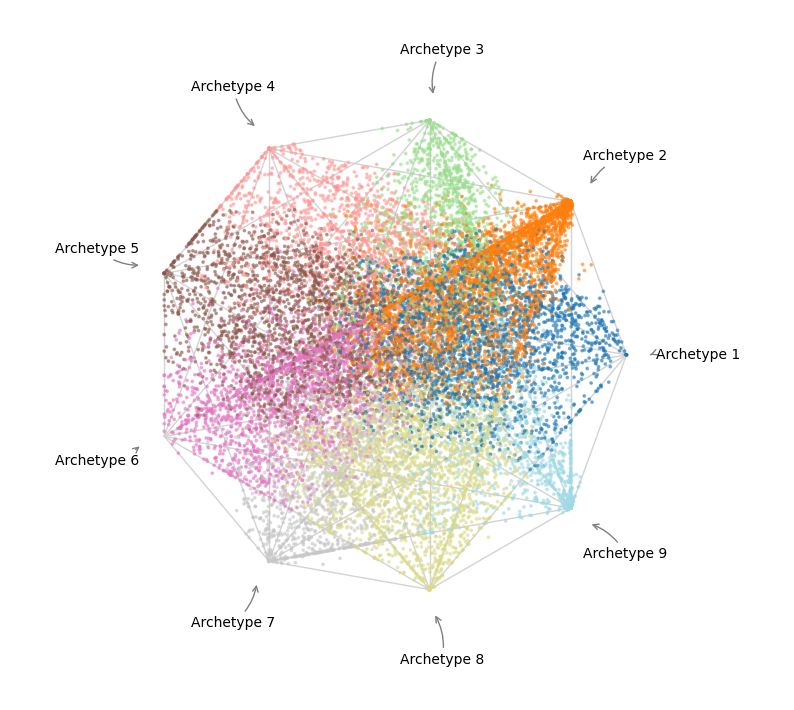

In [27]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels
otu_aa_swapped = otu_aa.copy()

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa.to_numpy(), alpha=0.5, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa.columns)


### Reordering (optional)
Sometimes the graph is quite messy, with prominent lines going through the middle. <br>
You may find it helpful to reorder the archetypes. This can be done by changing the array below in order
Caution: This depends on how many archetypes there are. You may have to change the ordering for each new result loaded. 

In [28]:
otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 5", "Archetype 8", "Archetype 2", "Archetype 6", "Archetype 7", "Archetype 9", "Archetype 3", "Archetype 4"]]

# otu_aa_swapped = otu_aa
# otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 2", "Archetype 8", "Archetype 7", "Archetype 4" , "Archetype 3", "Archetype 6", "Archetype 9", "Archetype 5", "Archetype 10"]]

Plotting the reordered Simplex

C:\Users\rayve\AppData\Local\Temp\ipykernel_26096\3839999831.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

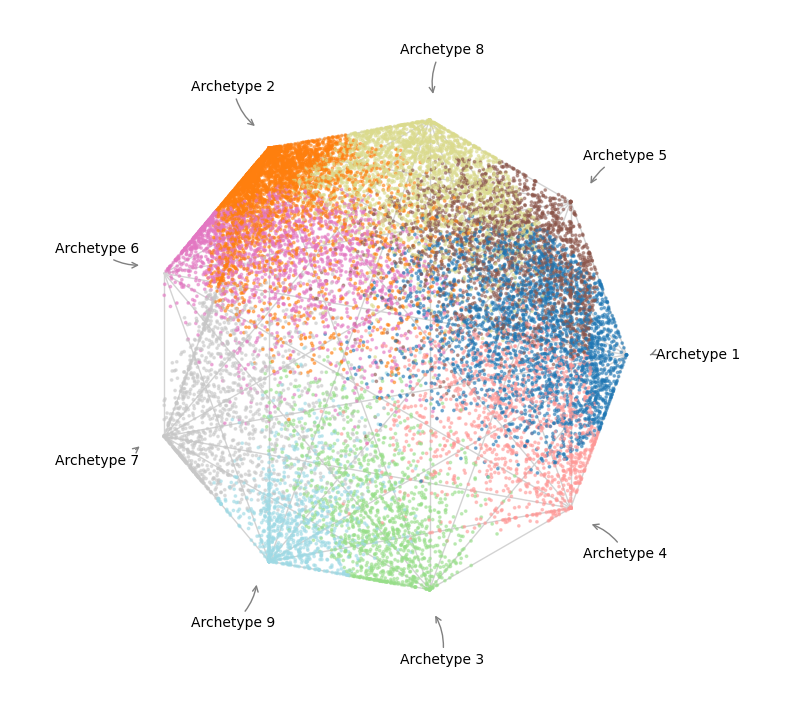

In [29]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa_swapped.to_numpy(), alpha=0.5, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa_swapped.columns)


## Plotting by Filter with Color
Below is the usage of the plot_simplex() utility for plotting by location. Here, `filter_cols` contains the columns of the sample dataset to filter by. <br>
`legend_type` parameter sets whether the values are "discrete" or "continuous"

Dropped 4021 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_26096\4050953862.py:68: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


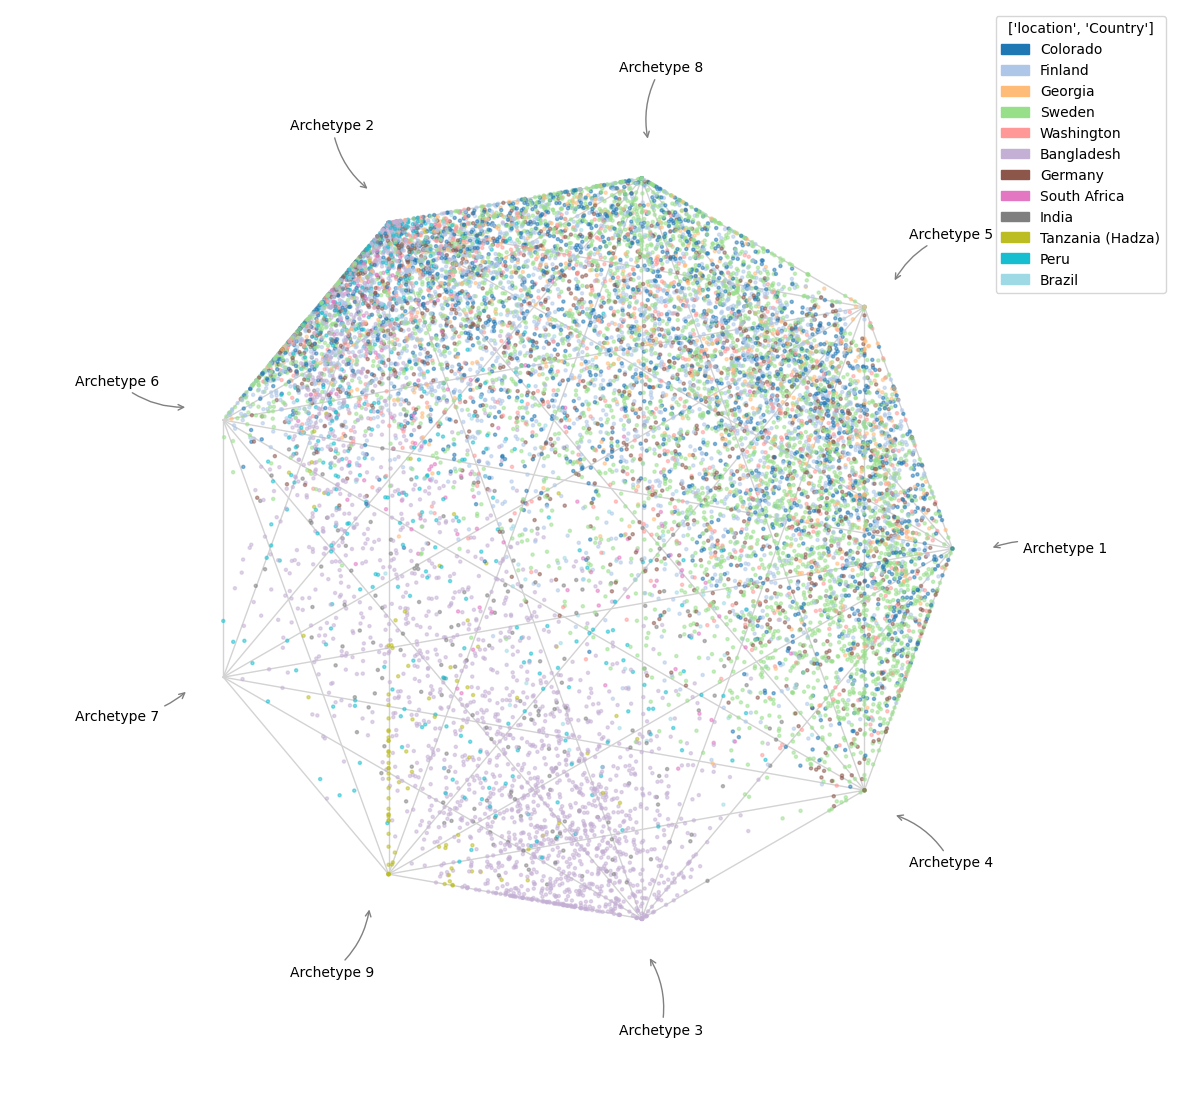

In [30]:
# FOR COUNTRY
filter_cols = ["location", "Country"]

plot_simplex(otu_aa_swapped, hadza_sam, filter_cols, cmap_name="tab20", legend_type="discrete", remove_nan=True)

Similarly, for age. This time, the `legend_type` is "continuous"

Dropped 4021 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_26096\4050953862.py:48: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(hadza_sam.loc[present_idx, col])
C:\Users\rayve\AppData\Local\Temp\ipykernel_26096\4050953862.py:68: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


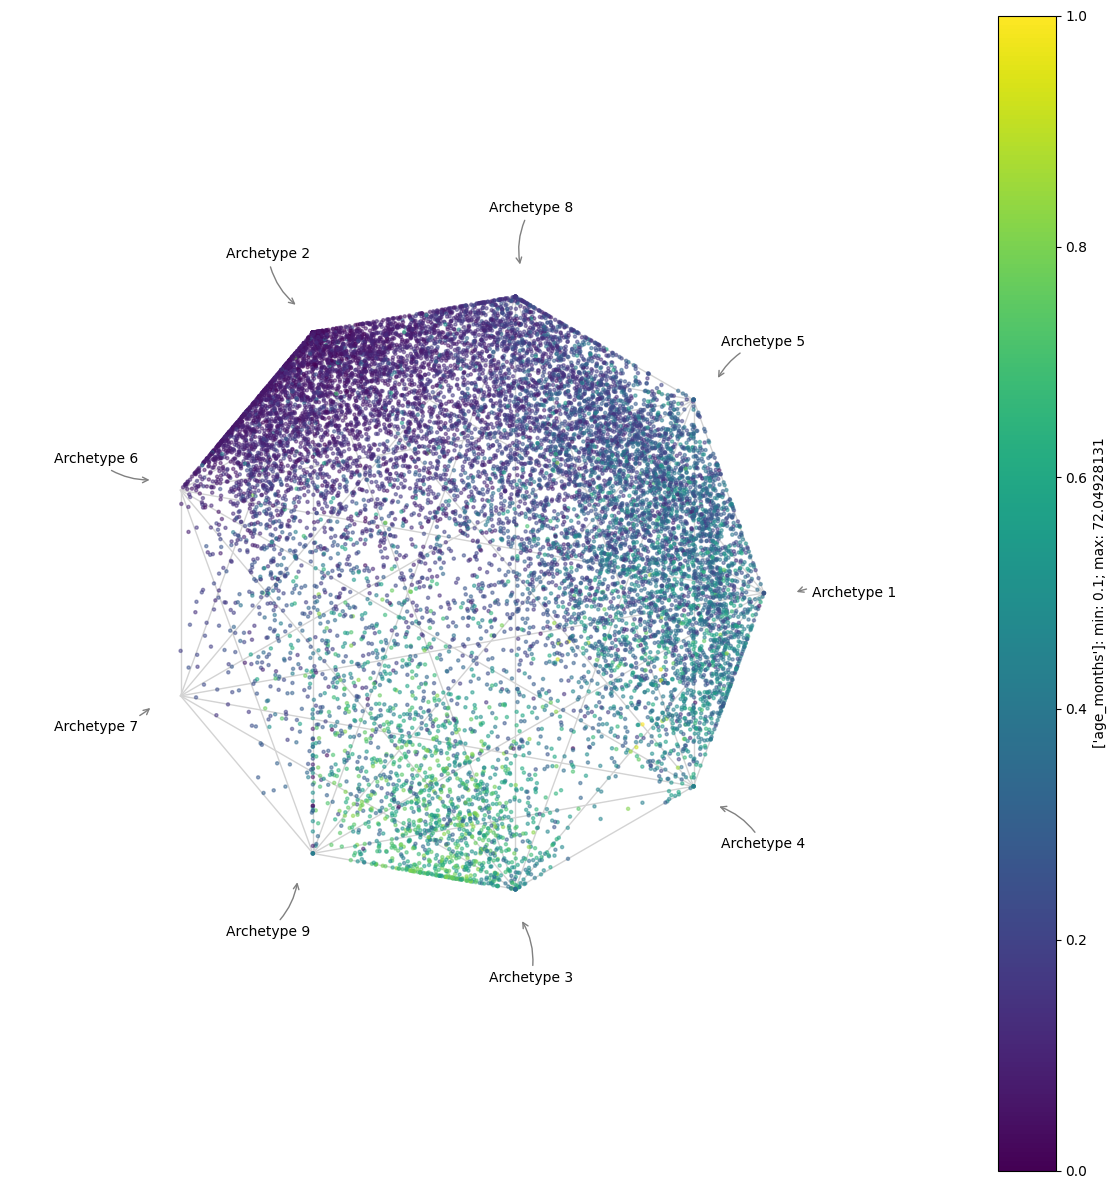

In [31]:
# FOR AGE

plot_simplex(otu_aa_swapped, hadza_sam, ["age_months"], "viridis", "continuous", remove_nan=True)

## Work In Progress: Display Archetype Composition

In [3]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = "hadza_otu_nov.tsv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_table(os.path.join(dataDir, otuFile), index_col=0)
tax = pd.read_table(os.path.join(dataDir, taxFile), index_col=0)



**Archetype 1**

***Label 1***: TACGTAGGGGGCAAGCGTTATCCGGATTTACTGGGTGTAAAGGGAGCGTAGACGGTGTGGCAAGTCTGATGTGAAAGGCATGGGCTCAACCTGTGGACTGCATTGGAAACTGTCATACTTGAGTGCCGGAGGGGTAAGCGGAATTCCTAGTGTAGCGGTGAAATGCGTAGATATTAGGAGGAACACCAGTGGCGAAGGCGGCTTACTGGACGGTAACTGACGTTGAGGCTCGAAAGCGTGGGGAGCAAACAGG 

***Label 2***: TACGTAGGGTGCAAGCGTTATCCGGAATTATTGGGCGTAAAGGGCTCGTAGGCGGTTCGTCGCGTCCGGTGTGAAAGTCCATCGCTTAACGGTGGATCCGCGCCGGGTACGGGCGGGCTTGAGTGCGGTAGGGGAGACTGGAATTCCCGGTGTAACGGTGGAATGTGTAGATATCGGGAAGAACACCAATGGCGAAGGCAGGTCTCTGGGCCGTTACTGACGCTGAGGAGCGAAAGCGTGGGGAGCGAACAGG 

***Label 3***: TACGTAGGGGGCTAGCGTTATCCGGAATTACTGGGCGTAAAGGGTGCGTAGGTGGTTTCTTAAGTCAGAGGTGAAAGGCTACGGCTCAACCGTAGTAAGCCTTTGAAACTGGGAAACTTGAGTGCAGGAGAGGAGAGTGGAATTCCTAGTGTAGCGGTGAAATGCGTAGATATTAGGAGGAACACCAGTTGCGAAGGCGGCTCTCTGGACTGTAACTGACACTGAGGCACGAAAGCGTGGGGAGCAAACAGG 

***Label 4***: TACGTAGGGGGCAAGCGTTATCCGGAATTACTGGGTGTAAAGGGTGCGTAGGTGGTATGGCAAGTCAGAAGTGAAAACCCAGGGCTTAACTCTGGGACTGCTTTTGAAACTGTCAGACTGGAGTGCAGGAGAGGTAAGCGGAATTCCTAGTGTAGC

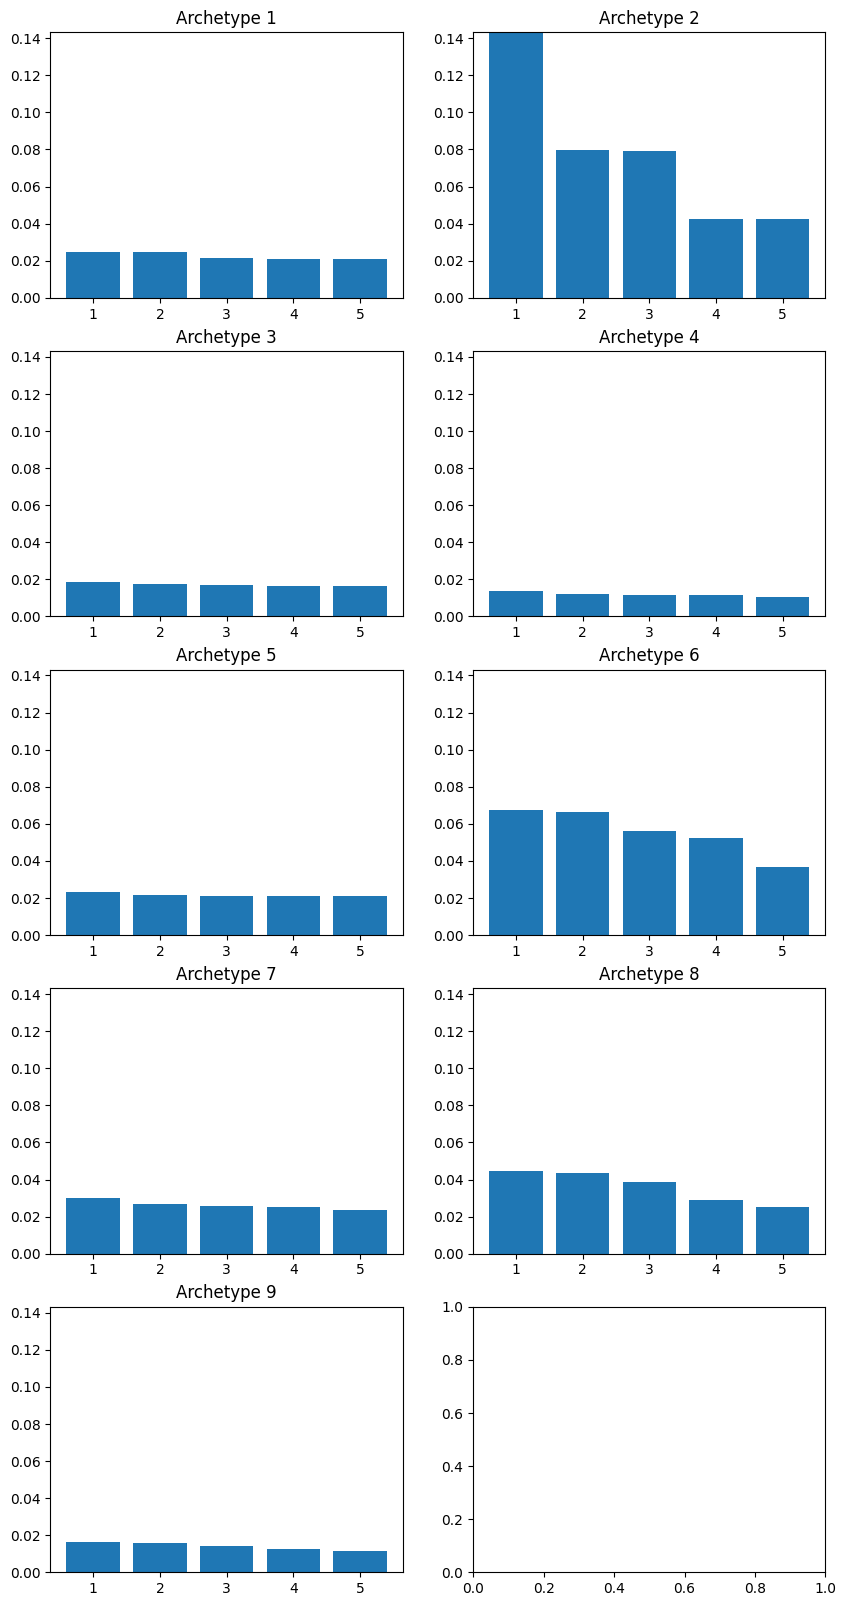

In [4]:
# archs = pd.DataFrame(aa_archetypes, columns=grouped_cols, index=[f"Archetype {i+1}" for i in range(n_archs)])
n_archs = len(aa_archetypes)
archs = pd.DataFrame(aa_archetypes, columns=otu.columns, index=[f"Archetype {i+1}" for i in range(n_archs)])

NUM_TAXA = 5

# Extract the top 5 taxa for each archetype

# For each row in archs, sort the values in descending order

tax_sorted_archs = archs.copy()
for i in range(archs.shape[0]):
    tax_sorted_archs.iloc[i] = tax_sorted_archs.iloc[i].sort_values(ascending=False)

# sorted_archs = archs.apply(lambda x: x.sort_values(ascending=False), axis=0)
top_n_taxa_archs = tax_sorted_archs.iloc[:, :NUM_TAXA]

# Go through each top taxa archetype, and find the column from which the value comes from

top_taxa_archs = [] # 2D Tuples (value, taxa)
for i,arch in top_n_taxa_archs.iterrows():
    top_taxa  = []
    for val in arch:
        # Find the column from whi  ch the value comes from in Row i from archs dataframe
        taxa = archs.loc[i][archs.loc[i] == val].index[0]
        top_taxa.append((val, taxa))

    top_taxa_archs.append(top_taxa)


# Find the percentage of each taxon in the archetype w.r.t archs
for i, arch in enumerate(top_taxa_archs):
    total = archs.loc[f"Archetype {i+1}"].sum()
    for j, (val, taxa) in enumerate(arch):
        top_taxa_archs[i][j] = (val/total, taxa)

# For each arch, add a new element ("Others") with the value 1 - sum of all other values
for i, arch in enumerate(top_taxa_archs):
    top_taxa_archs[i].append((1 - sum([val for val, taxa in arch]), "Others"))

# print(top_taxa_archs)

# # Make seperate pie charts for each archetype
# fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(10, 20))
# for i, arch in enumerate(top_taxa_archs):
#     vals = [val for val, taxa in arch]
#     labels = [taxa for val, taxa in arch]

#     print(f"**Archetype {i+1}**")
#     print()
#     for k, label in enumerate(labels):
#         print(f"***Label {k+1}***: {label} \n")
#     print("\n")
#     plotLabels = [f"{i+1}" for i in range(len(labels)-1)] + ["Others"]
#     ax[i // 2, i % 2].pie(vals, labels=plotLabels, autopct='%1.1f%%')
#     ax[i // 2, i % 2].set_title(f"Archetype {i+1}")

# plt.show()


# Make similar graphs but for bar plot, make sure to color the bars, and label them with respective index as above
# Set the same y-axis for all bar plots, which is the maximum value of all archetypes in top_taxa_archs

max_val = max([max([val for val, taxa in arch][:-1]) for arch in top_taxa_archs])

fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(10, 20))
for i, arch in enumerate(top_taxa_archs):
    vals = [val for val, taxa in arch]
    labels = [taxa for val, taxa in arch]

    print(f"**Archetype {i+1}**")
    print()
    for k, label in enumerate(labels):
        print(f"***Label {k+1}***: {label} \n")
    print("\n")
    plotLabels = [f"{i+1}" for i in range(len(labels)-1)] + ["Others"]
    ax[i // 2, i % 2].bar(plotLabels[:-1], vals[:-1])
    ax[i // 2, i % 2].set_title(f"Archetype {i+1}")
    ax[i // 2, i % 2].set_ylim(0, max_val)



In [5]:
import xml.etree.ElementTree as ET

def parseBlastXml(source): 

    taxa_hits = {}

    # tree = ET.parse(ET.fromstring(source))
    root = ET.fromstring(source)

    # Find all the hits, store them in a list of dictionaries, include sub children as well
    hits = []
    for iteration in root.findall(".//Iteration"):
        taxa_hits[iteration.find("Iteration_query-def").text] = []

        for hit in iteration.findall(".//Iteration_hits/Hit"):
            hit_dict = {}
            for child in hit:
                try: 
                    hit_dict[child.tag] = float(child.text) 
                except:
                    hit_dict[child.tag] = child.text
                if(child.tag == "Hit_hsps"):
                    hit_dict["Hsps"] = {}
                    hsps = child.findall(".//Hsp")[0].findall("./")
                    for hsp in hsps:
                        try: 
                            hit_dict["Hsps"][hsp.tag] = float(hsp.text)
                        except ValueError as e:
                            hit_dict["Hsps"][hsp.tag] = hsp.text

            taxa_hits[iteration.find("Iteration_query-def").text].append(hit_dict)


    return taxa_hits

# with open("my_blast.xml", "r") as f:
#     hits = parseBlastXml(f.read())
#     print(hits)


In [12]:
# write all the taxa in FASTA format file

def writeFasta(taxa, outPath):
    # Create the file if not exists
    with open(outPath, "a") as out_stream:
        out_stream.write(f">{taxa}\n")
        out_stream.write(f"{taxa}\n")

for arch in top_taxa_archs:
    for val, taxa in arch:
        if taxa == "Others":
            continue
        writeFasta(taxa, f"temp.fasta")


In [13]:
from Bio import Blast

with open ("temp.fasta", "r") as in_stream:
    src = in_stream.read()

result_stream = Blast.qblast("blastn", "ref_prok_rep_genomes", src)

with open("my_blast.xml", "wb") as out_stream:
    out_stream.write(result_stream.read())

result_stream.close()

In [6]:
with open("my_blast.xml", "r") as f:
    taxa_hits = parseBlastXml(f.read())

NUM_HITS = 3
filtered_hits = {}

for taxa, hits in taxa_hits.items():
    sorted_hits = sorted(hits, key=lambda x: x["Hsps"]["Hsp_evalue"])
    filtered_hits[taxa] = sorted_hits[:NUM_HITS]



C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
C:\Users\rayve\AppData\Local\Temp\ipykernel_24084\3237906308.py:35: UserWarning: set_ticklabels() should only be used 

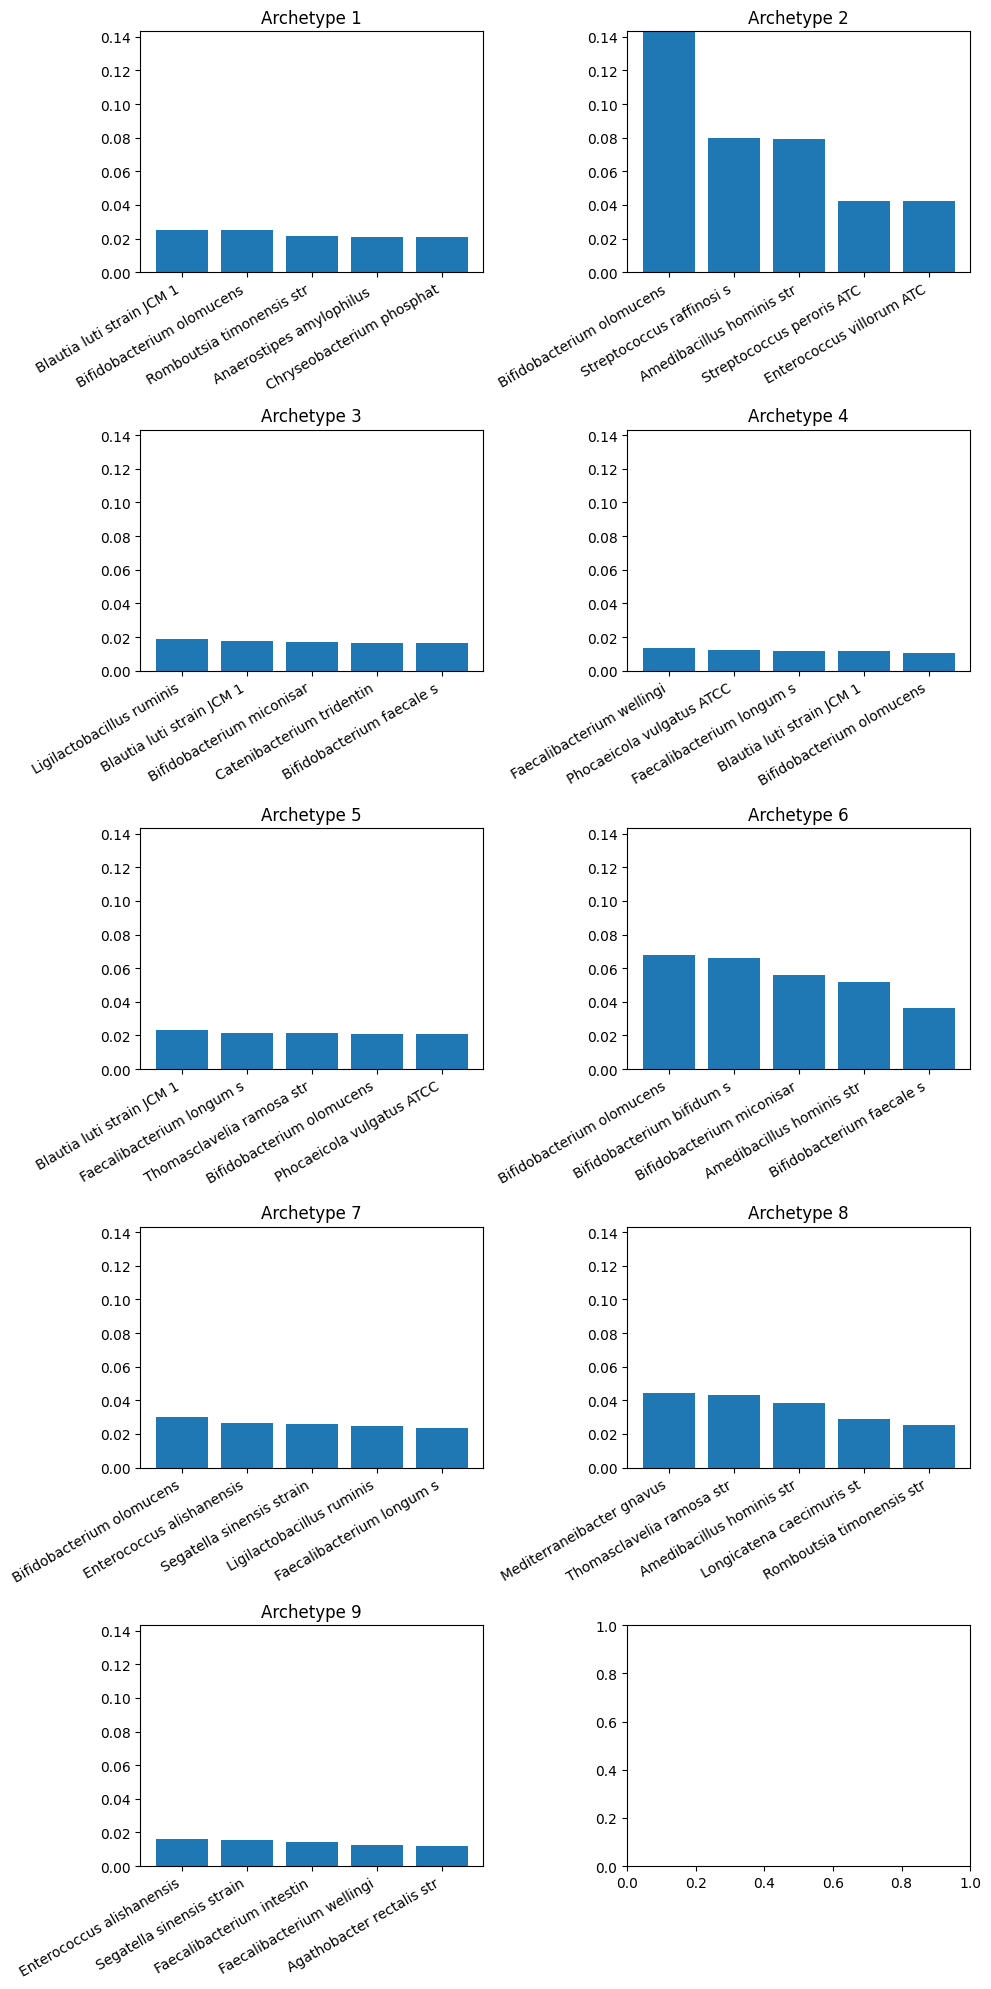

In [48]:
max_val = max([max([val for val, taxa in arch][:-1]) for arch in top_taxa_archs])

fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(10, 20))

labelled_top_taxa_archs = []


# Take top taxa archs and copy it into labelled_top_taxa_archs using loops
for i, arch in enumerate(top_taxa_archs):
    labelled_top_taxa_archs.append([])
    for val, taxa in arch:
        if taxa == "Others":
            labelled_top_taxa_archs[i].append([val, taxa])
            continue
        labelled_top_taxa_archs[i].append((val, filtered_hits[taxa]))


MAX_LABEL_LEN = 25

# I wanna kill myself this is so shit ohmygod TODO FIX
for i, arch in enumerate(labelled_top_taxa_archs):
    vals = [val for val, taxa in arch]
    labels = [taxa[0]["Hit_def"][:MAX_LABEL_LEN] for val, taxa in arch[:-1]]
    labels.append("Others")
    # print(labels[0]["Hit_def"])
    # print(f"**Archetype {i+1}**")
    # print()
    # for k, label in enumerate(labels):
    #     print(f"***Label {k+1}***: {label} \n")
    # print("\n")
    plotLabels = [f"{i+0}" for i in range(len(labels)-1)] + ["Others"]
    ax[i // 2, i % 2].bar(labels[:-1], vals[:-1])
    ax[i // 2, i % 2].set_title(f"Archetype {i+1}")
    ax[i // 2, i % 2].set_ylim(0, max_val)
    ax[i // 2, i % 2].set_xticklabels(ax[i // 2, i % 2].get_xticklabels(), rotation=30, ha='right')
fig.tight_layout()



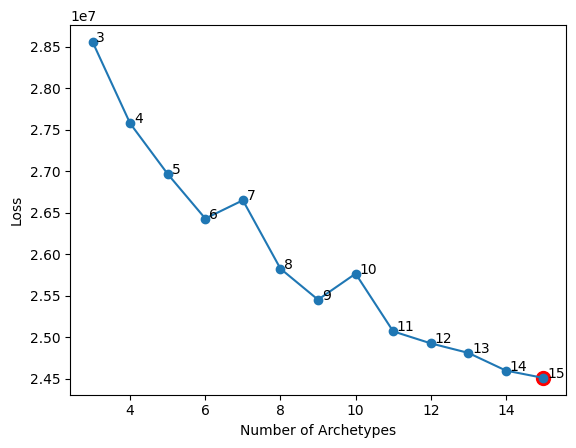

In [34]:
# Read all json files from /results/SBATCH_N3_N12, and plot the loss vs n_archetypes
import glob
import json

jsonFiles = glob.glob("results/SBATCH_N3_N15_NoPC_NoGlom/*.json")

losses = []

nIdx_archs = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


# Create a dict with keys n_archs and values losses from the appropriate json files
arch_losses = {}

for n in nIdx_archs:
    for j in jsonFiles:
        if f"K{n}_" in j:
            otu_dict = json.load(open(j, "r"))
            arch_losses[n] = otu_dict["loss"][-1]    


plt.plot(arch_losses.keys(), arch_losses.values(), marker="o")
plt.xlabel("Number of Archetypes")
plt.ylabel("Loss")

# Label the losses on the plot up to 3 significant digits
pad = 0.1
for i, txt in enumerate(nIdx_archs):
    plt.annotate(f"{txt}", (nIdx_archs[i] + pad, arch_losses[txt] + pad))

# Plot the smallest loss in green
min_loss = min(arch_losses.values())
min_key = [key for key, value in arch_losses.items() if value == min_loss][0]
plt.scatter(min_key, min_loss, color="red", s=100)

plt.show()

